# 01 — Dataset Selection & EDA

## Call Center Agent Performance Analysis

- **Dataset:** [AppTek Call-Center Dialogues](https://huggingface.co/datasets/apptek-com/apptek_callcenter_dialogues) (`diarization`).
- **Selection:** Compared 16 datasets and 15 papers. AppTek ranked highest (96/100).
- **Process:** Explored metadata, selected 12 calls, inspected sample audio, and saved the selection manifest.
- **Evaluation:** Reference transcripts and speaker labels are used for evaluation only. No ASR is performed here.

**Environment:** Google Colab (CPU).

In [ ]:
%pip -q install "huggingface_hub>=0.26,<2" "pandas>=2.0" "matplotlib>=3.7" "soundfile>=0.12" "tqdm>=4.60"

In [ ]:
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import json, random, posixpath
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
from IPython.display import Audio, display
from huggingface_hub import HfApi, hf_hub_download
from tqdm.auto import tqdm

REPO_ID = "apptek-com/apptek_callcenter_dialogues"
CONFIG = "diarization"
SEED = 42
ACCENTS_TARGET = ["en-US_General", "en-GB", "en-IN", "en-AU"]
CALLS_PER_ACCENT = 3
ROOT = Path("data")
META_DIR = ROOT / "metadata"
RAW_DIR = ROOT / "raw_samples"
OUT_DIR = ROOT / "processed"
for folder in [META_DIR, RAW_DIR, OUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
print("Working directory:", Path.cwd().resolve())

Working directory: /content


## 1. Dataset Metadata

Pin the dataset version and load only `metadata.jsonl` files to avoid downloading the full dataset. Audio will be downloaded separately when needed.

In [ ]:
api = HfApi()
info = api.dataset_info(REPO_ID)
revision = info.sha
files = api.list_repo_files(REPO_ID, repo_type="dataset", revision=revision)
metadata_paths = sorted(
    p for p in files if p.startswith(f"{CONFIG}/") and p.endswith("/metadata.jsonl")
)
print(f"Dataset revision: {revision}")
print(f"Available metadata groups: {len(metadata_paths)}")
print("Examples:", metadata_paths[:5])
assert metadata_paths, "No diarization metadata found; check the repository structure."
(OUT_DIR / "provenance.json").write_text(json.dumps({
    "repo_id": REPO_ID,
    "config": CONFIG,
    "revision": revision,
    "retrieved_utc": datetime.now(timezone.utc).isoformat(),
    "license": "CC BY-SA 4.0",
    "use": "Evaluation and analysis only; no ASR training/fine-tuning",
    "metadata_paths": metadata_paths,
}, indent=2, ensure_ascii=False), encoding="utf-8")

Dataset revision: b98967d9946f7f59f58d08624a2a00fe98fe0219
Available metadata groups: 14
Examples: ['diarization/en-AU/metadata.jsonl', 'diarization/en-CA/metadata.jsonl', 'diarization/en-CN/metadata.jsonl', 'diarization/en-GB/metadata.jsonl', 'diarization/en-GB_SCT/metadata.jsonl']


912

## 2. Load metadata from all accents (no WAV files)

Every row in the `diarization` configuration represents a merged, two-speaker conversation. The `segments` list contains reference start/end timestamps, role (`customer` / `agent`), speaker ID and text.

In [ ]:
calls = []
for metadata_path in tqdm(metadata_paths, desc="Metadata groups"):
    local = hf_hub_download(
        repo_id=REPO_ID, repo_type="dataset", filename=metadata_path,
        revision=revision, local_dir=str(META_DIR)
    )
    with open(local, encoding="utf-8") as f:
        for line_no, line in enumerate(f, start=1):
            if not line.strip():
                continue
            row = json.loads(line)
            row["_metadata_path"] = metadata_path
            row["_line_number"] = line_no
            calls.append(row)
print("Calls loaded:", len(calls))
print("First-row fields:", list(calls[0].keys()))
print("First-segment fields:", list(calls[0].get("segments", [{}])[0].keys()))
assert calls, "No metadata rows found."

Metadata groups:   0%|          | 0/14 [00:00<?, ?it/s]

metadata.jsonl:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

metadata.jsonl:   0%|          | 0.00/1.17M [00:00<?, ?B/s]

metadata.jsonl:   0%|          | 0.00/997k [00:00<?, ?B/s]

metadata.jsonl:   0%|          | 0.00/1.41M [00:00<?, ?B/s]

metadata.jsonl:   0%|          | 0.00/1.52M [00:00<?, ?B/s]

... (6 outputs left out)

metadata.jsonl:   0%|          | 0.00/1.27M [00:00<?, ?B/s]

metadata.jsonl:   0%|          | 0.00/1.28M [00:00<?, ?B/s]

metadata.jsonl:   0%|          | 0.00/1.12M [00:00<?, ?B/s]

Calls loaded: 873
First-row fields: ['file_name', 'duration', 'domain', 'accent', 'segments', '_metadata_path', '_line_number']
First-segment fields: ['start', 'end', 'role', 'speaker_id', 'gender', 'text']


## 3. Validate fields, roles, timestamps, durations and basic coverage

The checks are diagnostics rather than automatic claims of dataset correctness. Natural overlaps between speakers are expected, so we do **not** mark overlapping segments as invalid by themselves.

In [ ]:
records = []
violations = []
for i, row in enumerate(calls):
    segs = row.get("segments") or []
    roles = {str(s.get("role", "")).lower() for s in segs}
    duration = row.get("duration")
    row_id = f"row_{i:04d}"
    filename = row.get("file_name", "")
    if not filename:
        violations.append((row_id, "missing file_name"))
    if duration is None or float(duration) <= 0:
        violations.append((row_id, "missing/invalid duration"))
    if not {"agent", "customer"}.issubset(roles):
        violations.append((row_id, f"both roles not found: {sorted(roles)}"))
    invalid_times = 0
    missing_text = 0
    for s in segs:
        start, end = s.get("start"), s.get("end")
        if start is None or end is None or float(start) < 0 or float(end) <= float(start) or (duration and float(end) > float(duration) + 1.0):
            invalid_times += 1
        if not str(s.get("text", "")).strip():
            missing_text += 1
    if invalid_times:
        violations.append((row_id, f"invalid timestamps in {invalid_times} segments"))
    records.append({
        "row_id": row_id, "file_name": filename, "accent": row.get("accent"),
        "domain": row.get("domain"), "duration_sec": float(duration) if duration else None,
        "segments": len(segs), "customer_segments": sum(str(s.get("role", "")).lower() == "customer" for s in segs),
        "agent_segments": sum(str(s.get("role", "")).lower() == "agent" for s in segs),
        "missing_text_segments": missing_text, "invalid_timestamp_segments": invalid_times,
        "metadata_path": row["_metadata_path"],
    })
df = pd.DataFrame(records)
print(f"Calls: {len(df)} | accents: {df.accent.nunique()} | domains: {df.domain.nunique()}")
print(f"Total call duration: {df.duration_sec.sum()/3600:.1f} hours")
print(f"Total reference segments: {df.segments.sum():,}")
print(f"Missing transcript segments: {df.missing_text_segments.sum():,}")
print(f"Timestamp violations: {df.invalid_timestamp_segments.sum():,}")
print(f"Calls with issue(s): {len(set(r for r, _ in violations))}")
display(df.head(6))
if violations:
    display(pd.DataFrame(violations[:30], columns=["row_id", "issue"]))

Calls: 873 | accents: 14 | domains: 16
Total call duration: 151.1 hours
Total reference segments: 94,679
Missing transcript segments: 0
Timestamp violations: 0
Calls with issue(s): 0


,row_id,file_name,accent,domain,duration_sec,segments,customer_segments,agent_segments,missing_text_segments,invalid_timestamp_segments,metadata_path
0,row_0000,audio/en_AU_Agriculture_1586330.wav,en-AU,agriculture,432.000,65,22,43,0,0,diarization/en-AU/metadata.jsonl
1,row_0001,audio/en_AU_Agriculture_1592662.wav,en-AU,agriculture,889.200,157,66,91,0,0,diarization/en-AU/metadata.jsonl
2,row_0002,audio/en_AU_Aviation_1585418.wav,en-AU,aviation,809.250,127,42,85,0,0,diarization/en-AU/metadata.jsonl
3,row_0003,audio/en_AU_Aviation_1586330.wav,en-AU,aviation,354.000,51,18,33,0,0,diarization/en-AU/metadata.jsonl
4,row_0004,audio/en_AU_Aviation_1592663.wav,en-AU,aviation,903.482,151,67,84,0,0,diarization/en-AU/metadata.jsonl
5,row_0005,audio/en_AU_Aviation_1593397.wav,en-AU,aviation,908.383,76,31,45,0,0,diarization/en-AU/metadata.jsonl


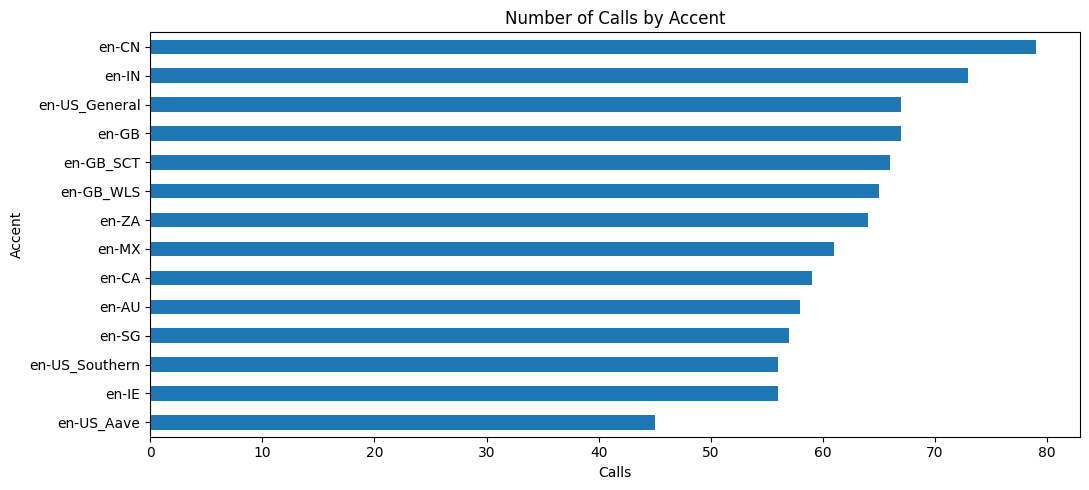

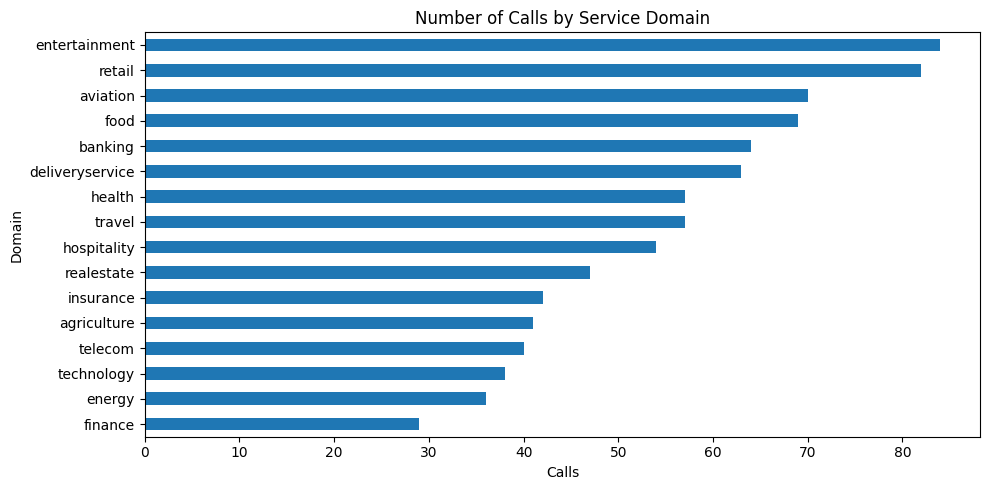

,duration_sec,segments,customer_segments,agent_segments
count,873.00,873.00,873.00,873.00
mean,622.95,108.45,46.44,62.01
std,166.96,42.39,20.34,25.82
min,204.79,29.00,12.00,16.00
25%,495.68,78.00,31.00,43.00
50%,617.25,100.00,42.00,57.00
75%,713.53,134.00,58.00,75.00
max,1235.93,263.00,133.00,210.00


In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))
df.accent.value_counts().sort_values().plot(kind="barh", ax=ax)
ax.set(title="Number of Calls by Accent", xlabel="Calls", ylabel="Accent")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
df.domain.value_counts().sort_values().plot(kind="barh", ax=ax)
ax.set(title="Number of Calls by Service Domain", xlabel="Calls", ylabel="Domain")
plt.tight_layout()
plt.show()

display(df[["duration_sec", "segments", "customer_segments", "agent_segments"]].describe().round(2))

## 4. Reproducible representative sampling (12 calls)

We select **3 different domains per accent**, across 4 requested accents, using a fixed seed. This is a *convenience-stratified sample for a practical assessment*, not a statistically representative test set of all accents or calls. We also retain metadata pointers for traceability.

**Call count is a starting point.** We will consider extending to ~20 only after the end-to-end pipeline runs and we estimate compute time.

In [ ]:
rng = random.Random(SEED)
selected = []
for accent in ACCENTS_TARGET:
    group = df[df.accent == accent]
    if group.empty:
        raise ValueError(f"Accent {accent} not present. Available accents: {sorted(df.accent.dropna().unique())}")
    domains = sorted(group.domain.dropna().unique())
    if len(domains) < CALLS_PER_ACCENT:
        raise ValueError(f"Only {len(domains)} unique domains for accent {accent}")
    rng.shuffle(domains)
    for domain in domains[:CALLS_PER_ACCENT]:
        candidates = group[group.domain == domain]
        # Use stable row ordering and seeded RNG for reproducibility
        chosen_idx = rng.randrange(len(candidates))
        selected.append(candidates.sort_values("file_name").iloc[chosen_idx].to_dict())
sample = pd.DataFrame(selected).reset_index(drop=True)
sample.insert(0, "call_id", [f"CALL_{i:03d}" for i in range(1, len(sample)+1)])
cols = ["call_id", "accent", "domain", "duration_sec", "segments", "customer_segments", "agent_segments", "file_name", "metadata_path", "row_id"]
sample[cols].to_csv(OUT_DIR / "selected_calls.csv", index=False)
sample[cols].to_json(OUT_DIR / "selected_calls.json", orient="records", indent=2, force_ascii=False)
print("Shortlist saved. Count:", len(sample))
display(sample[["call_id", "accent", "domain", "duration_sec", "segments"]])

Shortlist saved. Count: 12


,call_id,accent,domain,duration_sec,segments
0,CALL_001,en-US_General,food,386.637,47
1,CALL_002,en-US_General,hospitality,630.749,64
2,CALL_003,en-US_General,entertainment,701.906,187
3,CALL_004,en-GB,hospitality,421.525,83
4,CALL_005,en-GB,retail,611.108,127
5,CALL_006,en-GB,entertainment,603.482,94
6,CALL_007,en-IN,telecom,631.712,103
7,CALL_008,en-IN,insurance,625.664,92
8,CALL_009,en-IN,health,422.208,65
9,CALL_010,en-AU,banking,420.000,86


## 5. Download **one** merged two-speaker audio WAV and listen

This step is the practical check that we can obtain the original **audio bytes**, not only metadata or transcripts. It downloads **one** WAV file, checks its sample rate/channels/duration, and plays the first 30 seconds. Later we will download only the full shortlist.

The audio relative path in `file_name` is joined with the directory containing its metadata file.

In [ ]:
first = sample.iloc[0]
repo_audio_path = posixpath.normpath(posixpath.join(
    posixpath.dirname(first["metadata_path"]), first["file_name"]
))
assert repo_audio_path in set(files), (
    f"Audio path not found: {repo_audio_path}. Inspect metadata field and repo tree."
)
audio_local = hf_hub_download(
    repo_id=REPO_ID, repo_type="dataset", filename=repo_audio_path,
    revision=revision, local_dir=str(RAW_DIR)
)
audio_info = sf.info(audio_local)
print("Call:", first["call_id"], "| accent:", first["accent"], "| domain:", first["domain"])
print("Repo path:", repo_audio_path)
print("Audio info:", audio_info)
print("Metadata duration(s):", round(first["duration_sec"], 2))
assert audio_info.frames > 0, "Downloaded audio file is empty."
assert audio_info.channels == 1, "Expected mono mixed audio; inspect if dataset structure changed."
assert abs(audio_info.duration - first["duration_sec"]) < 2.0, "Unexpected duration mismatch: inspect."
# Load only the first 30 seconds, not the entire recording.
with sf.SoundFile(audio_local, "r") as f:
    head = f.read(frames=min(f.frames, f.samplerate*30), dtype="float32")
    sample_rate = f.samplerate
display(Audio(head, rate=sample_rate))

diarization/en-US_General/audio/en_US_Ge(…): reconstructing file:   0%|          |  0.00B / 12.4MB            

diarization/en-US_General/audio/en_US_Ge(…): downloading bytes:           |  0.00B            

Call: CALL_001 | accent: en-US_General | domain: food
Repo path: diarization/en-US_General/audio/en_US_General_Food_1586724.wav
Audio info: /content/data/raw_samples/diarization/en-US_General/audio/en_US_General_Food_1586724.wav
samplerate: 16000 Hz
channels: 1
duration: 06:26.637 min
format: WAV (Microsoft) [WAV]
subtype: Signed 16 bit PCM [PCM_16]
Metadata duration(s): 386.64


## 6. Reference Speaker Turns

Inspect AppTek's reference speaker labels, timestamps, and transcripts for evaluating model predictions in later notebooks.

In [ ]:
chosen = calls[int(first["row_id"].split("_")[1])]
turns = pd.DataFrame(chosen["segments"])
print("Reference segments:", len(turns))
turn_columns = [c for c in ["start", "end", "role", "speaker_id", "text"] if c in turns.columns]
display(turns[turn_columns].head(15))
print("First 10 reference speaker roles:", turns["role"].head(10).tolist())

Reference segments: 47


,start,end,role,speaker_id,text
0,11.84,19.80,agent,speaker_en_us_general_male_4,"Ring ring, hi there, this is Leo from Feast an..."
1,20.64,26.42,customer,speaker_en_us_general_female_10,"Hi Leo, yeah this is Ashley I'm l~ looking int..."
2,27.04,37.28,agent,speaker_en_us_general_male_4,"Ohh I love a good team lunch, nothing brings c..."
3,40.04,51.44,customer,speaker_en_us_general_female_10,"Wow you sound very enthusiastic about this, I ..."
4,52.64,62.65,agent,speaker_en_us_general_male_4,"Challenge accepted vegan check, gluten free, d..."
5,63.04,65.76,agent,speaker_en_us_general_male_4,We can make sure everyone leaves the table hap...
6,66.24,66.84,customer,speaker_en_us_general_female_10,Perfect.
7,67.44,72.87,customer,speaker_en_us_general_female_10,(um) I also wanted to know about pricing per p...
8,73.54,82.98,agent,speaker_en_us_general_male_4,"(ah) numbers and norms, my two favorite things..."
9,83.54,84.94,agent,speaker_en_us_general_male_4,And menu options.


First 10 reference speaker roles: ['agent', 'customer', 'agent', 'customer', 'agent', 'agent', 'customer', 'customer', 'agent', 'agent']


## 7. Save a machine-readable EDA report (and perform final checks)

In [ ]:
report = {
    "dataset": REPO_ID,
    "config": CONFIG,
    "revision": revision,
    "total_calls_in_config": int(len(df)),
    "accent_count": int(df.accent.nunique()),
    "domain_count": int(df.domain.nunique()),
    "total_call_audio_hours": round(float(df.duration_sec.sum()/3600), 2),
    "total_reference_segments": int(df.segments.sum()),
    "calls_with_both_roles": int(((df.agent_segments > 0) & (df.customer_segments > 0)).sum()),
    "total_missing_text_segments": int(df.missing_text_segments.sum()),
    "total_invalid_timestamp_segments": int(df.invalid_timestamp_segments.sum()),
    "sample_size": int(len(sample)),
    "sample_accents": sorted(sample.accent.unique().tolist()),
    "sample_domains": sorted(sample.domain.unique().tolist()),
    "random_seed": SEED,
    "first_audio_repo_path": repo_audio_path,
    "first_audio_sample_rate": audio_info.samplerate,
    "first_audio_channels": audio_info.channels,
    "first_audio_duration_seconds": round(audio_info.duration, 3),
    "note": "Reference segments/roles are dataset annotations, not model outputs; this notebook does not perform ASR.",
}
(OUT_DIR / "dataset_profile.json").write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(report, indent=2, ensure_ascii=False))
assert len(sample) == len(ACCENTS_TARGET)*CALLS_PER_ACCENT
assert sample.call_id.is_unique
assert all(sample.groupby("accent")["domain"].nunique() == CALLS_PER_ACCENT)
print("\n✓ Stage 2 completed. Save notebook + processed manifest + profile; move to 02_transcription.ipynb.")

{
  "dataset": "apptek-com/apptek_callcenter_dialogues",
  "config": "diarization",
  "revision": "b98967d9946f7f59f58d08624a2a00fe98fe0219",
  "total_calls_in_config": 873,
  "accent_count": 14,
  "domain_count": 16,
  "total_call_audio_hours": 151.07,
  "total_reference_segments": 94679,
  "calls_with_both_roles": 873,
  "total_missing_text_segments": 0,
  "total_invalid_timestamp_segments": 0,
  "sample_size": 12,
  "sample_accents": [
    "en-AU",
    "en-GB",
    "en-IN",
    "en-US_General"
  ],
  "sample_domains": [
    "banking",
    "entertainment",
    "food",
    "health",
    "hospitality",
    "insurance",
    "retail",
    "telecom"
  ],
  "random_seed": 42,
  "first_audio_repo_path": "diarization/en-US_General/audio/en_US_General_Food_1586724.wav",
  "first_audio_sample_rate": 16000,
  "first_audio_channels": 1,
  "first_audio_duration_seconds": 386.637,
  "note": "Reference segments/roles are dataset annotations, not model outputs; this notebook does not perform ASR."
}

*Source: [official dataset card](https://huggingface.co/datasets/apptek-com/apptek_callcenter_dialogues), [original paper](https://arxiv.org/abs/2604.27543).*